<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Victor/PracticaRegresionLineal23111511.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Práctica: Regresión lineal y optimización de R²**  
**Alumno:** Victor Manuel Landeros Ramirez
**Número de control:** 23111511

**APLICACION DE UN MODELO DE MACHINE LEARNING DE REGRESION LINEAL**

In [ ]:
# Opcional en Google Colab: montar Drive si el archivo no está en la sesión.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


En esta actividad usarás el archivo de datos `bigMartSales.csv`.

* `Item_Identifier`: ID de producto único
* `Item_Weight`: Peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: el porcentaje del área de exhibición total de todos los productos en una tienda asignado al producto en particular.
* `Item_Type`: La categoría a la que pertenece el producto.
* `Item_MRP`: Precio de venta máximo (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: El año en que se estableció la tienda.
* `Outlet_Size`: El tamaño de la tienda en términos de superficie cubierta.
* `Outlet_Location_Type`: El tipo de ciudad en la que se encuentra la tienda.
* `Outlet_Type`: si el outlet es solo una tienda de comestibles o algún tipo de supermercado.

* **`Item_Outlet_Sales`**: Ventas del producto en la tienda concreta. Ésta es la variable de resultado que se va a predecir.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

Descarga el archivo: `bigMartSales.csv` y guarda, en un dataframe (`sales_df`), todos sus registros.

In [7]:
from pathlib import Path
ruta = Path('/content/drive/MyDrive/Colab Notebooks/bigMartSales.csv')
sales_df = pd.read_csv(ruta)
print('Dimensiones:', sales_df.shape)
display(sales_df.head())

Dimensiones: (8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


ANALISIS DE DATOS

In [8]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [9]:
# Determinando la cantidad de valores únicos por columna
sales_df.nunique()

,0
Item_Identifier,1559
Item_Weight,415
Item_Fat_Content,5
Item_Visibility,7880
Item_Type,16
Item_MRP,5938
Outlet_Identifier,10
Outlet_Establishment_Year,9
Outlet_Size,3
Outlet_Location_Type,3


Como las variables `Item_Identifier` y `Outlet_Identifier` son solo variables de ID, asumimos que no tienen ningún poder predictivo para predecir la variable dependiente: `Item_Outlet_Sales`.

In [10]:
sales_df.drop(['Item_Identifier','Outlet_Identifier'], axis=1, inplace=True)

In [11]:
# Estadísticas descriptivas de las variables numéricas
sales_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800


In [12]:
# Estadísticas descriptivas de las variables de texto
sales_df.describe(include = 'object').T

,count,unique,top,freq
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577


In [14]:
# Se hace una lista de variables numéricas y otra de categóricas.
num_cols = sales_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = sales_df.select_dtypes(exclude=np.number).columns.tolist()

In [16]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(sales_df[column].value_counts())
    print('-' * 50)

Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
--------------------------------------------------
Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
--------------------------------------------------
Outlet_Size
Outlet_Size
Medium    2793
Small     2388
High       932
Name: count, dtype: int64
--------------------------------------------------
Outlet_Location_Type
Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388

In [17]:
# Se determinan porcentaje de nulos por columna
sales_df.isnull().mean() * 100

,0
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,0.000000
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Establishment_Year,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000
Outlet_Type,0.000000
Item_Outlet_Sales,0.000000


**Análisis univariado de variables numéricas**

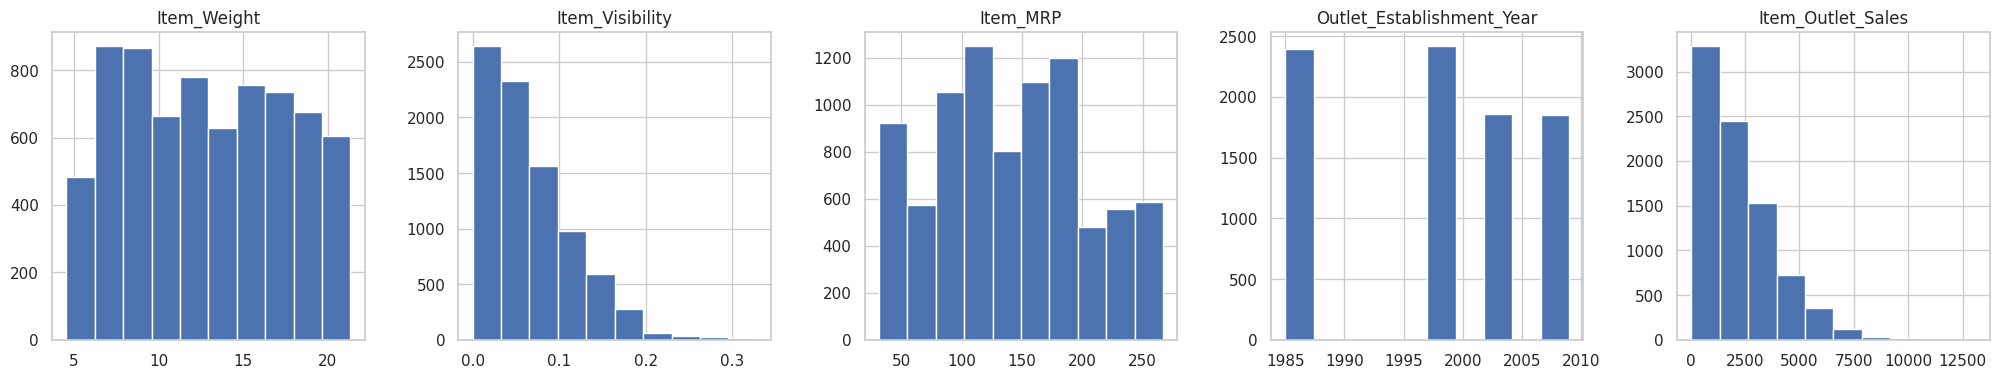

In [18]:
sales_df.hist(figsize=(25,4), layout=(1,5))
plt.show()

/tmp/ipykernel_760/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_760/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_760/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_760/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot

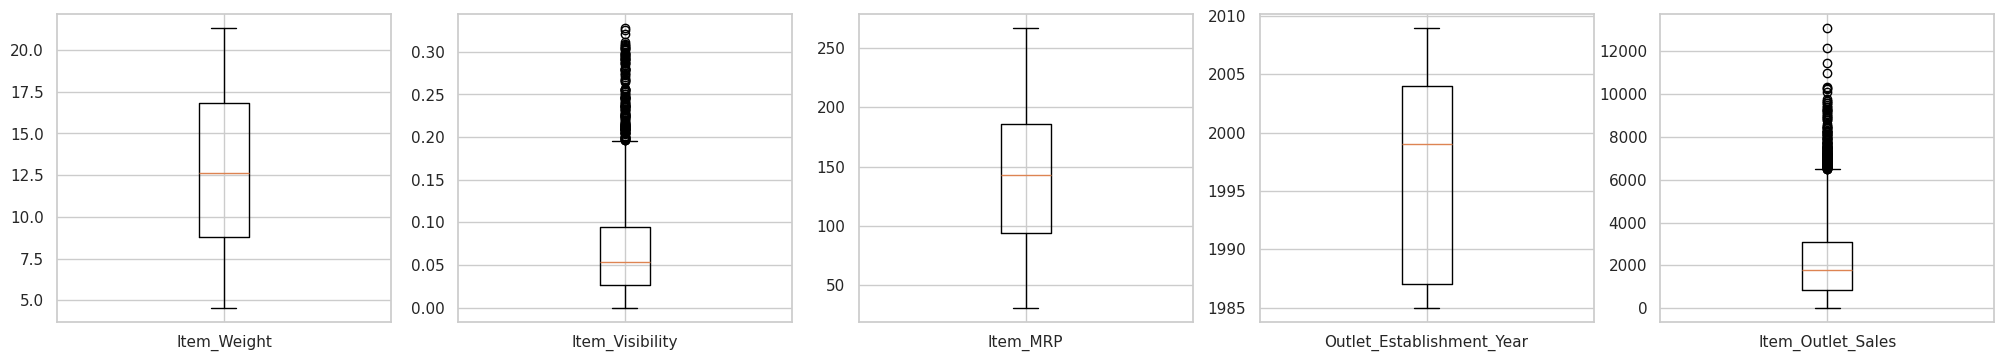

In [19]:
fig, axes = plt.subplots(1,5, figsize=(25,4))
axes = axes.ravel()
for col, ax in zip(sales_df[num_cols], axes):
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])

**Análisis univariado de variables categóricas**

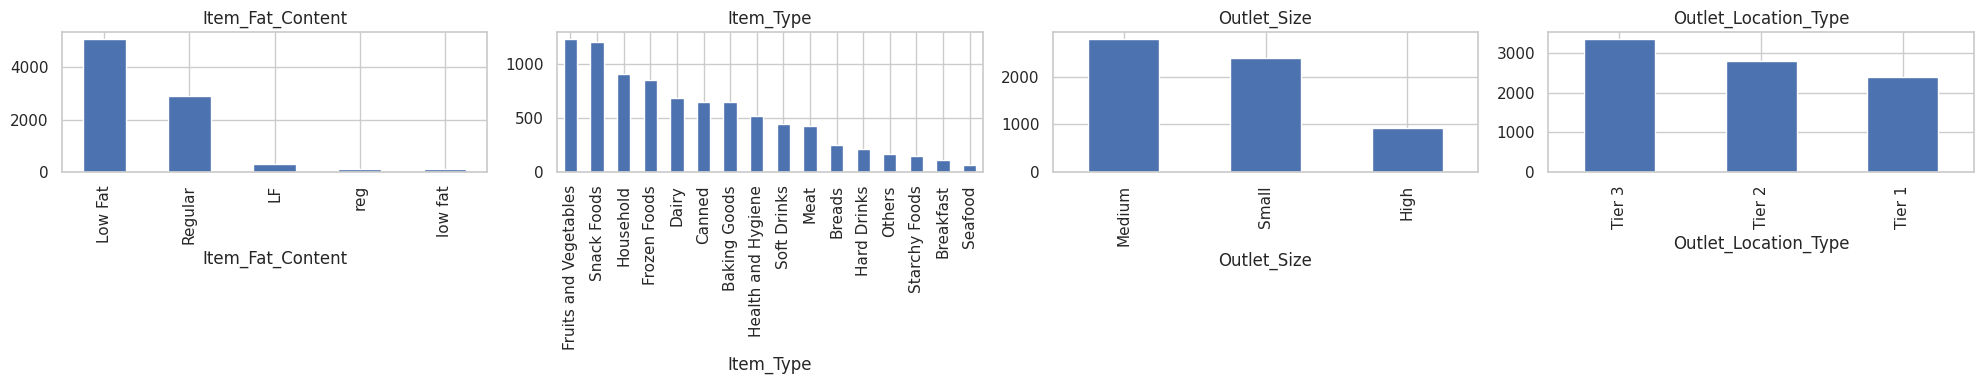

In [20]:
fig, axes = plt.subplots(1,4,figsize=(20,4))
for col, ax in zip(cat_cols,axes):
    sales_df[col].value_counts().plot.bar(ax=ax, title=col)
plt.tight_layout();plt.show()

En `Ite_Fat_Content` hay categorías expresadas de diferente forma:
*   Low Fat = low fat = LF
*   Regular = reg

Se unifica, para sólo dejar dos valores: Low Fat y Regular



In [21]:
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Low Fat' if x == 'low fat' or x == 'LF' else x)
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Regular' if x == 'reg' else x)

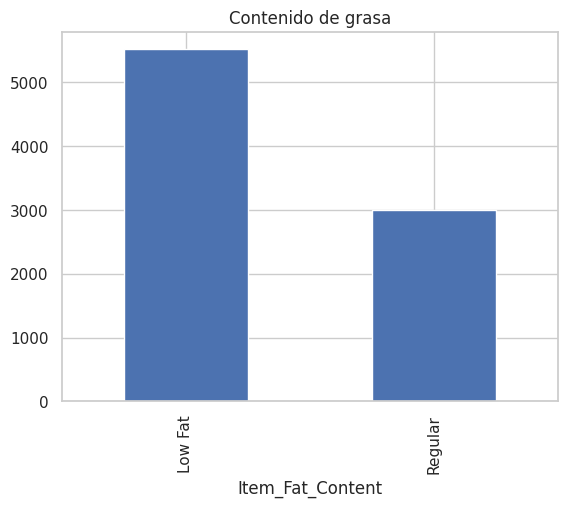

In [22]:
sales_df['Item_Fat_Content'].value_counts().plot.bar(title='Contenido de grasa'); plt.show()

**Análisis bivariado**

<Axes: >

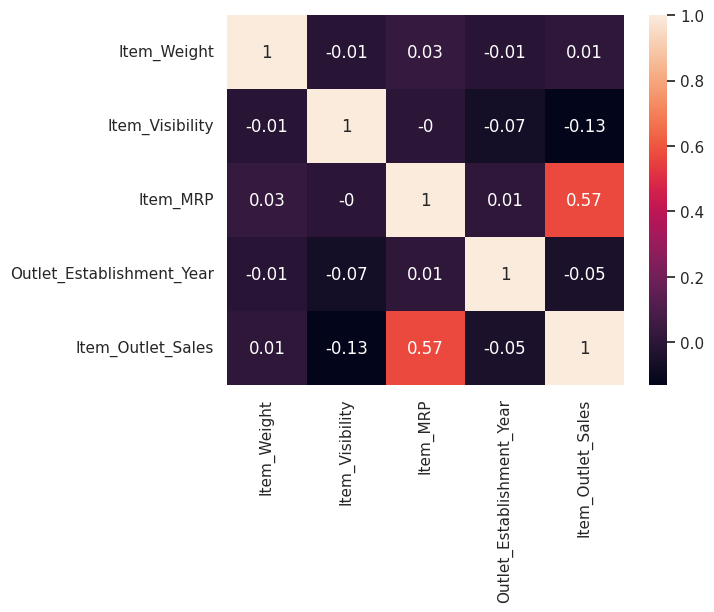

In [23]:
sns.heatmap(round(sales_df.corr(numeric_only=True),2), annot = True)

Del gráfico anterior, parece que solo la variable independiente `Item_MRP` tiene una relación lineal moderada con la variable dependiente `Item_Outlet_Sales`. Se verifica con diagramas de dispersión.

<Axes: xlabel='Item_MRP', ylabel='Item_Outlet_Sales'>

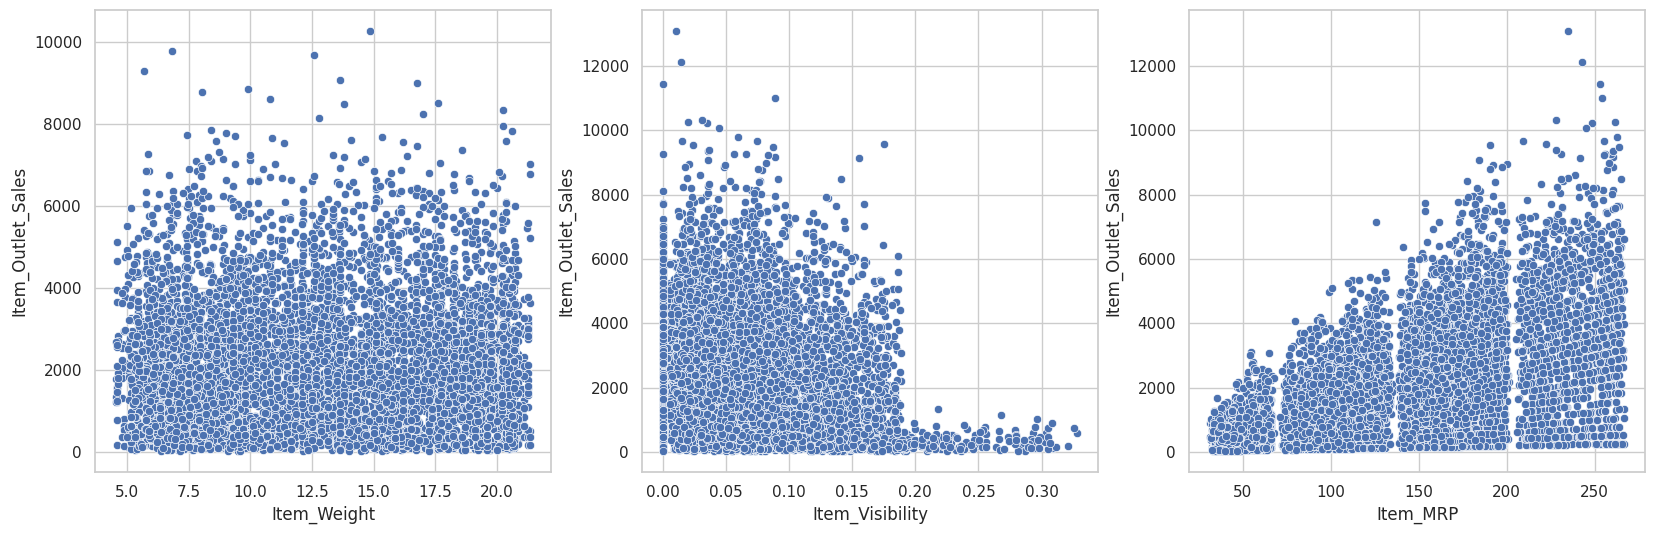

In [24]:
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='Item_Weight', y='Item_Outlet_Sales', data=sales_df, ax=axes[0])
sns.scatterplot(x='Item_Visibility', y='Item_Outlet_Sales', data=sales_df, ax=axes[1])
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=sales_df, ax=axes[2])

Se crea una nueva característica `Outlet_Age` que indica la antigüedad del outlet.

In [25]:
# Usamos un año de referencia fijo para que los resultados sean reproducibles.
sales_df['Outlet_Age'] = 2026 - sales_df['Outlet_Establishment_Year']
sales_df.drop(columns='Outlet_Establishment_Year', inplace=True)
print('Antigüedad calculada para', sales_df['Outlet_Age'].nunique(), 'valores distintos')

Antigüedad calculada para 9 valores distintos


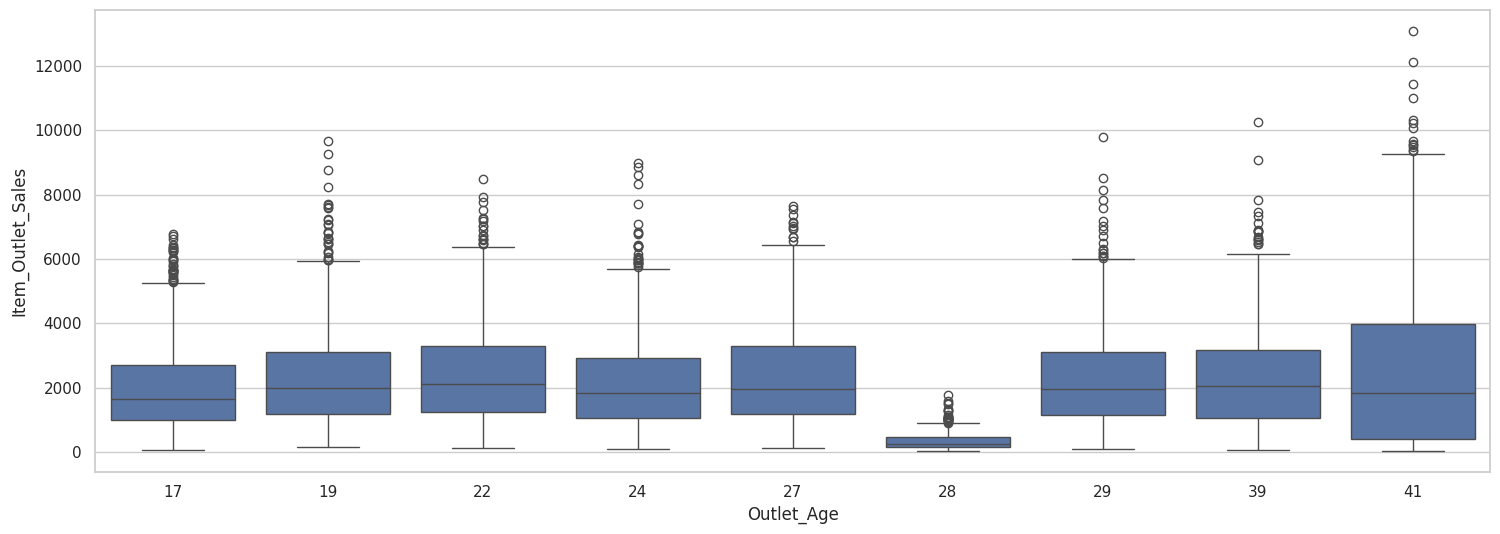

In [26]:
fig = plt.figure(figsize = (18, 6))
sns.boxplot(x = 'Outlet_Age', y = 'Item_Outlet_Sales', data = sales_df);

**INCIO MODELO MACHINE LEARNING**

INGENIERIA DE CARACTERISTICAS

Se especifican cuales seran las variables de entrada 'X' (Caracteristica) y cual sera la varible predictora 'y' (variable salida o
tambien Objetivo)

In [27]:
# Se separan las variables del dataframe: en X quedan los predictores y en y la variable de respuesta o salida (Item_Outlet_Sales).
X = sales_df.drop('Item_Outlet_Sales', axis = 1) #variables de entrada - Caracteristica
y = sales_df['Item_Outlet_Sales'] #variable salida -variable predictora - Objetivo

**PARTICION DEL CONJUNTO DE DATOS**

In [28]:
# Se divide el conjunto en entrenamiento y prueba (80:20)
#80% conjunto de entrenamiento(train)
#20% para el conjunto de prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,#variable entrada
                                                y,#variable salida o predictora
                                                train_size=0.8, # tama;o conjunto entrenamiento
                                                random_state=1) #para mantener mismo conjunto de datos

PROCESAMIENTO

**CANALIZACION (PIPELINE)**

In [29]:
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                             OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
preprocessing = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_include=object))])

In [30]:
# Esto no es necesario, pero lo incluyo para que se visualicen los cambios que produce el pipeline "preprocessing" creado anteriormente
# Nótese que Xtrain queda con 27 columnas después del procesamiento, es decir, se utilizarán 27 predictores en el modelo (4 numéricos y 23 categóricos)

Xtrain_prepared = preprocessing.fit_transform(Xtrain)
Xtrain_prepared_df = pd.DataFrame(Xtrain_prepared, columns=preprocessing.get_feature_names_out(), index=Xtrain.index)
Xtrain_prepared_df

,num__Item_Weight,num__Item_Visibility,num__Item_MRP,num__Outlet_Age,cat__Item_Fat_Content_Regular,cat__Item_Type_Breads,cat__Item_Type_Breakfast,cat__Item_Type_Canned,cat__Item_Type_Dairy,cat__Item_Type_Frozen Foods,...,cat__Item_Type_Snack Foods,cat__Item_Type_Soft Drinks,cat__Item_Type_Starchy Foods,cat__Outlet_Size_Medium,cat__Outlet_Size_Small,cat__Outlet_Location_Type_Tier 2,cat__Outlet_Location_Type_Tier 3,cat__Outlet_Type_Supermarket Type1,cat__Outlet_Type_Supermarket Type2,cat__Outlet_Type_Supermarket Type3
1945,0.821375,0.272069,0.681925,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1720,0.761834,0.511783,0.615374,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1954,0.330158,0.164095,0.824788,0.083333,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1919,0.374814,0.496066,0.312702,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2461,0.155701,0.181846,0.423207,0.208333,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2895,0.479012,0.844906,0.531008,1.000000,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7813,0.479012,0.542624,0.100619,1.000000,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
905,0.791605,0.200402,0.500067,0.500000,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5192,0.300387,0.151094,0.054833,0.458333,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


**APLICA PREPROCESAMIENTO ANTERIOR PARA EL**

**ENTRENAMIENTO DEL MODELO REGRESION LINEAL**

In [31]:
# Modelo de referencia: regresión lineal múltiple.
lr_model = make_pipeline(preprocessing, LinearRegression())
lr_model.fit(Xtrain, ytrain)
predictions = lr_model.predict(Xtest)
rmse_lineal = np.sqrt(mean_squared_error(ytest, predictions))
r2_lineal = r2_score(ytest, predictions)
print(f'Regresión lineal | RMSE: {rmse_lineal:,.2f} | R²: {r2_lineal:.4f}')

Regresión lineal | RMSE: 1,144.38 | R²: 0.5582


**Interpretación del modelo inicial.** El RMSE expresa el tamaño típico del error de predicción en unidades de ventas, mientras que R² indica qué proporción de su variabilidad explica el modelo. Ambos valores se calculan en el conjunto de prueba, sin usarlo para entrenar.

## OPTIMIZACIÓN DEL MODELO Y COMPARACIÓN

**Objetivo:** explorar si es posible llegar a un R² de 0.70–0.75 sin alterar las ventas reales ni utilizar información del conjunto de prueba para entrenar. No se garantiza alcanzar ese intervalo: depende de la capacidad predictiva del dataset. Probamos métodos no lineales además de la regresión lineal inicial.

In [32]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

# Se emplean los mismos conjuntos de entrenamiento y prueba para una comparación justa.
# HistGradientBoosting usa las variables ya codificadas; los árboles capturan relaciones no lineales.
modelos = {
    'Regresión lineal': lr_model,
    'Random Forest': make_pipeline(preprocessing, RandomForestRegressor(
        n_estimators=180, min_samples_leaf=8, max_features=0.9, random_state=1, n_jobs=-1)),
    'Gradient Boosting': make_pipeline(preprocessing, HistGradientBoostingRegressor(
        max_iter=160, learning_rate=0.05, max_leaf_nodes=12,
        l2_regularization=15, min_samples_leaf=35, random_state=1))
}
resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(Xtrain, ytrain)
    pred = modelo.predict(Xtest)
    resultados.append({'Modelo': nombre,
                       'RMSE': np.sqrt(mean_squared_error(ytest, pred)),
                       'R²': r2_score(ytest, pred)})
resultados_df = pd.DataFrame(resultados).sort_values('R²', ascending=False)
display(resultados_df.round(4))

,Modelo,RMSE,R²
2,Gradient Boosting,1103.5273,0.5892
1,Random Forest,1122.6580,0.5748
0,Regresión lineal,1144.3828,0.5582


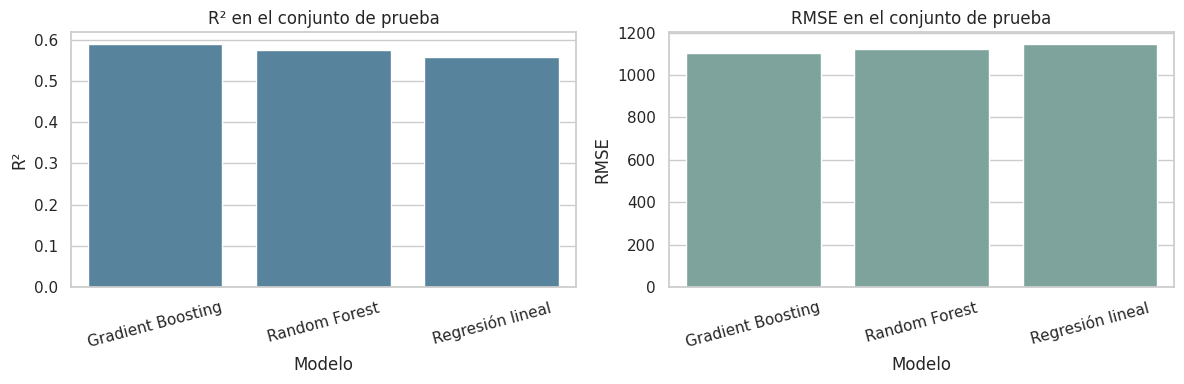

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=resultados_df, x='Modelo', y='R²', ax=axes[0], color='#4b87a8')
sns.barplot(data=resultados_df, x='Modelo', y='RMSE', ax=axes[1], color='#78a9a0')
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
axes[0].set_title('R² en el conjunto de prueba')
axes[1].set_title('RMSE en el conjunto de prueba')
plt.tight_layout()
plt.show()

### Interpretación y conclusión

La mejora se considera real solo si aumenta el R² **en datos no utilizados para entrenar** y, preferiblemente, disminuye el RMSE. Un algoritmo más complejo no necesariamente es mejor. El objetivo 0.70–0.75 es una referencia, no un resultado que deba forzarse. Además, comparar modelos en el mismo test puede introducir sesgo de selección; para una evaluación más rigurosa conviene seleccionar hiperparámetros con validación cruzada y reservar el test para el final.

In [34]:
mejor = resultados_df.iloc[0]
print(f"Mejor resultado observado: {mejor['Modelo']}")
print(f"R² = {mejor['R²']:.4f}; RMSE = {mejor['RMSE']:.2f}")
if 0.70 <= mejor['R²'] <= 0.75:
    print('Se alcanzó el intervalo objetivo de R².')
elif mejor['R²'] > 0.75:
    print('El resultado superó el intervalo objetivo.')
else:
    print('No se alcanzó R² de 0.70; se reporta el resultado real sin modificarlo.')

Mejor resultado observado: Gradient Boosting
R² = 0.5892; RMSE = 1103.53
No se alcanzó R² de 0.70; se reporta el resultado real sin modificarlo.


Lo que seguiría es hacer más transformaciones para mejorar el resultado. Por ejemplo:

* Aplicar una transformación (log, box-cox,...) para hacer que la distribución de `Item_Visibility` tenga una forma más normal, porque está sesgada.

* Usar StandarScaler o RobustScaler en lugar de MinMax.
* Aplicar OrdinalEncoder a algunas categóricas, en lugar de OneHotEncoder.

In [35]:
# Se puede tener acceso a los pasos ejecutados en el pipeline
lr_model.named_steps

{'columntransformer': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('minmaxscaler',
                                                   MinMaxScaler())]),
                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7cba1c185550>),
                                 ('cat',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('onehotencoder',
                                                   OneHotEncoder(drop='first',
                                                                 handle_unknown='ignore',
                                                                 sparse_output=False))])

In [36]:
# Una vez ubicado en un paso, por ejemplo en la regresión lineal ('linearregression'), se puede tener acceso a sus atributos
# Para mostrar la intercepción o beta_0
lr_model.named_steps['linearregression'].intercept_

np.float64(274.6134468529333)

In [37]:
# Para mostrar los coeficientes: beta_1, beta_2, ... beta_n
# En este caso se obtienen 27 coeficientes, uno por predictor
lr_model.named_steps['linearregression'].coef_

array([  28.62355263,  -97.09612341, 3678.93686232, -883.7484864 ,
         36.0930557 ,    9.09628309,  -15.7209235 ,   34.68740649,
       -100.45813405,  -39.04913619,   38.07938416,  -23.89284596,
         10.9988591 ,  -62.51983653,  -33.90791199,  -36.06410826,
        283.24072408,   15.10818476,  -74.74109576,   35.98874243,
       -839.68268244, -746.65228891, -202.1755319 , -395.31896407,
       1509.68985198, 1243.4315047 , 3872.29804368])

In [38]:
# Para mostrar los transformadores ejecutados
lr_model.named_steps['columntransformer']

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('minmaxscaler',
                                                  MinMaxScaler())]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x7cba1c185550>),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x7cba14124f50>)])

In [39]:
# Para tener acceso a un transformador en particular
lr_model.named_steps['columntransformer'].named_transformers_['num']

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('minmaxscaler', MinMaxScaler())])

In [40]:
# Para tener acceso a los atributos de un transformador en particular
# Como sólo se tienen 4 predictores numéricos, se calcula el mínimo de cada uno
lr_model.named_steps['columntransformer'].named_transformers_['num'].named_steps['minmaxscaler'].min_

array([-0.27121167,  0.        , -0.13281075, -0.70833333])